# Volatility Regimes and Overnight/Daytime Predictability, CL 2021–2026 (#32)

This notebook collects the outputs of the two #32 scripts: the realized-variance features built from 1-minute bars, and the regime-interaction tests of the ON + DAY model for the last half hour. It reads only the files the scripts write and computes nothing they do not. Run the scripts first, from the repository root:

```bash
python -m src.build_volatility_features --config config/volatility_features.yaml
python -m src.analyze_volatility_regimes --config config/volatility_regimes.yaml
```

The write-up is `reports/volatility_regimes_results.md`. Slopes are × 100 with Newey-West standard errors; OOS R² is in percent.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(path for path in (Path("."), Path("..")) if (path / "reports/tables").exists())
tables = root / "reports/tables"
figures = root / "reports/figures"

features = pd.read_parquet(root / "data/processed/cl_volatility_features.parquet")
feature_summary = pd.read_csv(root / "data/processed/cl_volatility_features_summary.csv")
manifest = json.loads((tables / "volatility_regimes.manifest.json").read_text())
regressions = pd.read_csv(tables / "volatility_regimes_regressions.csv")
slopes = pd.read_csv(tables / "volatility_regimes_slopes.csv")
counts = pd.read_csv(tables / "volatility_regimes_counts.csv")
oos = pd.read_csv(tables / "volatility_regimes_oos.csv")
robustness = pd.read_csv(tables / "volatility_regimes_robustness.csv")
by_year = pd.read_csv(tables / "volatility_regimes_by_year.csv")

pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
REGIMES = {"combined_vol": "Combined RV", "day_vol": "Daytime RV", "overnight_vol": "Overnight RV", "trailing_5d_vol": "Trailing 5-day RV"}


def estimate(frame: pd.DataFrame, value: str, error: str) -> pd.Series:
	return frame.apply(lambda row: f"{row[value]:.2f} ({row[error]:.2f})", axis=1)

## 1. Realized-variance features

Overnight (previous 13:30 to 08:00 CT) and daytime (08:00 to 13:00 CT) realized variance of the contract held on each trade date, from 1-minute log returns, with returns across a halt of 60+ minutes recorded as reopening jumps rather than summed. The summary file lists the checks: every sample path starts and ends at the #27 reference prices.

In [2]:
feature_summary

,check,value,note
0,trade_dates,1448,2021-01-04 to 2026-10-07
1,sample_trade_dates,1436,paper_sample with both paths
2,paths_on,1448/1448,missing:
3,endpoints_match_on,1436/1436,path starts and ends at the reference prices (...
4,returns_on,"median 1044, min 819, max 2278",1-minute returns per path in the sample
5,jumps_on,"{1: 1401, 2: 35}",reopening returns excluded per path: count of ...
6,jump_share_on,0.154,share of the window's total squared returns th...
7,max_gap_on,"{7.0: 11, 8.0: 8, 9.0: 5, 10.0: 4, 11.0: 4}",longest kept gap (minutes) per path: count of ...
8,vol_on_pct,"median 1.405, p90 2.555, max 12.458","realized volatility per window, percent"
9,paths_day,1448/1448,missing:


In [3]:
sample = features[features["sample"]]
sample[["vol_on_pct", "vol_day_pct", "vol_rod_pct", "n_on", "n_day", "jumps_on", "overnight_missing_minutes"]].describe().T

,count,mean,std,min,25%,50%,75%,max
vol_on_pct,"1,436.000",1.677,0.933,0.685,1.137,1.405,1.938,12.458
vol_day_pct,"1,436.000",1.520,0.624,0.634,1.112,1.370,1.759,6.825
vol_rod_pct,"1,436.000",2.284,1.081,1.066,1.616,2.011,2.593,14.205
n_on,"1,436.000","1,065.620",184.642,819.000,"1,035.000","1,044.000","1,048.000","2,278.000"
n_day,"1,436.000",299.990,0.165,296.000,300.000,300.000,300.000,300.000
jumps_on,"1,436.000",1.024,0.154,1.000,1.000,1.000,1.000,2.000
overnight_missing_minutes,"1,436.000",5.937,18.173,0.000,0.000,1.000,5.000,217.000


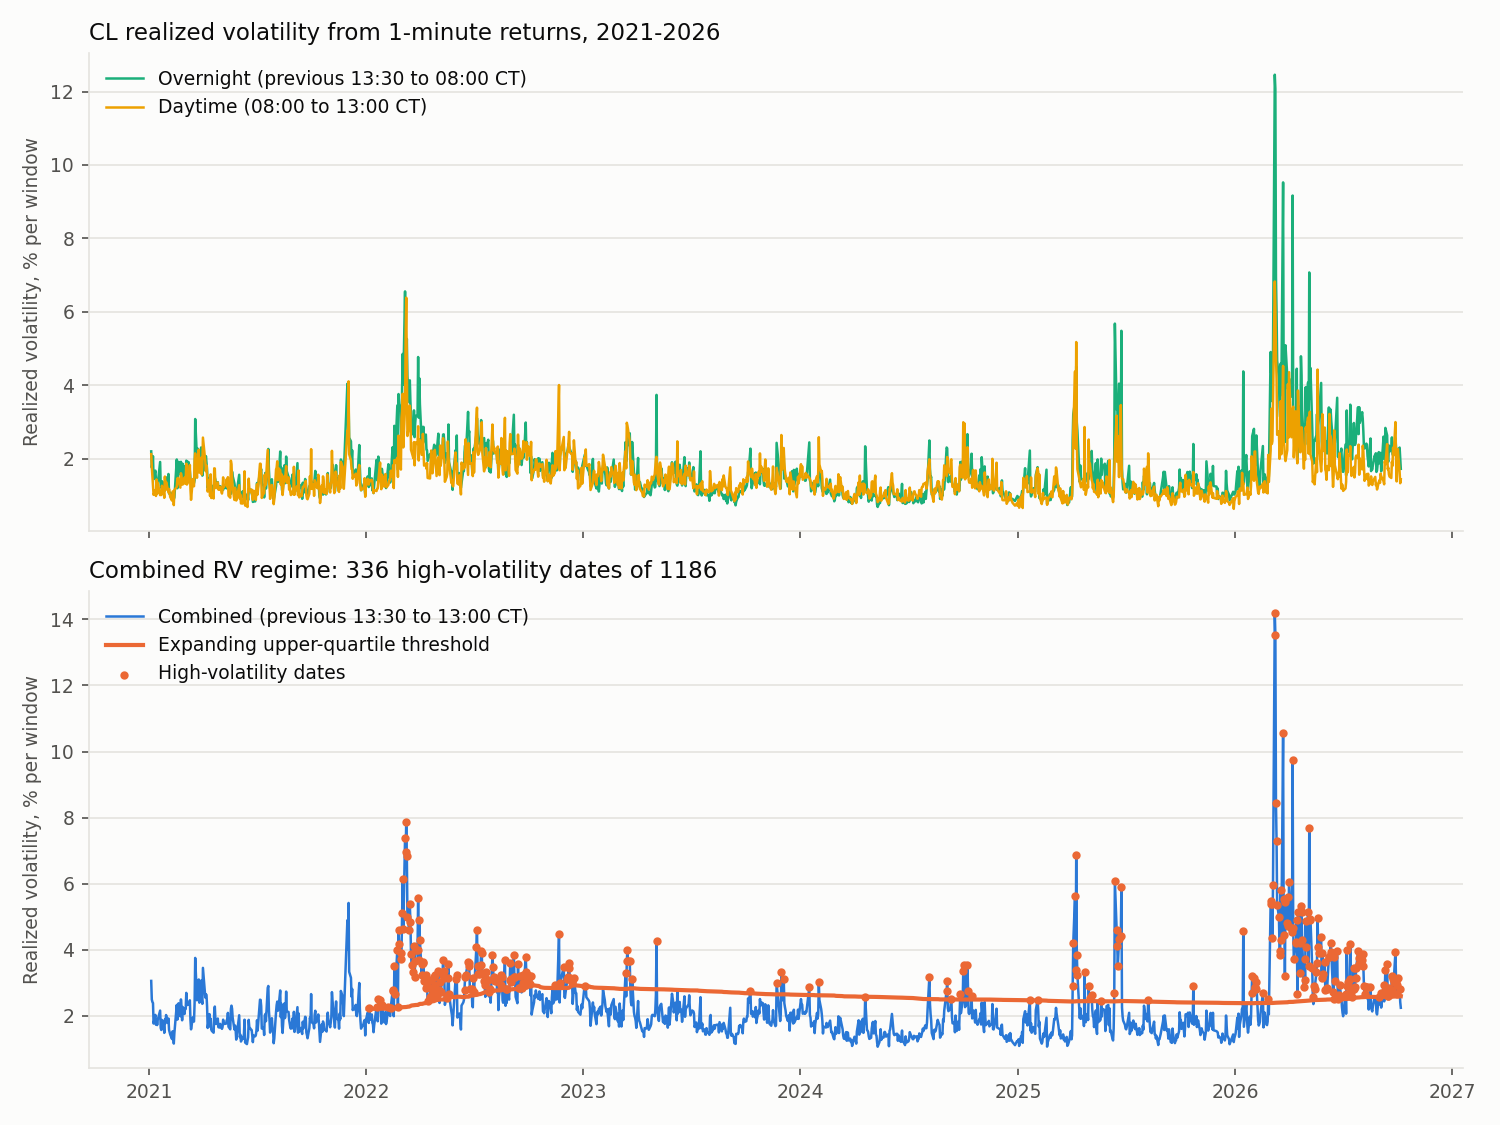

In [4]:
display(Image(filename=figures / "volatility_regimes_measures.png", width=950))

## 2. Regimes

A date is high volatility when its measure exceeds the upper quartile of the measure over the earlier dates (expanding threshold, 250-date burn-in). The regime sample, counts, and the dispersion of LH in each regime: high-volatility dates have about twice the LH standard deviation.

In [5]:
pd.Series(
	{
		"merged observations": manifest["sample"]["merged_observations"],
		"dates": manifest["sample"]["dates"],
		"regression observations per regime": manifest["sample"]["regression_observations"],
		"Newey-West lags": manifest["hac_lags_used"],
		"interaction tests / Bonferroni level": f"{manifest['interaction_tests']} / {manifest['bonferroni_level']:.4f}",
	},
	name="value",
).to_frame()

,value
merged observations,1436
dates,2021-01-04 to 2026-10-07
regression observations per regime,"{'combined_vol': 1186, 'day_vol': 1186, 'overn..."
Newey-West lags,7
interaction tests / Bonferroni level,8 / 0.0063


In [6]:
counts[counts["variant"].eq("baseline")].assign(regime=lambda frame: frame["regime"].map(REGIMES))[
	["regime", "measure", "n", "n_low", "n_high", "first_date", "last_threshold_vol_pct", "measure_vol_low_pct", "measure_vol_high_pct", "lh_sd_low_pct", "lh_sd_high_pct", "lh_mean_low_bps", "lh_mean_high_bps"]
]

,regime,measure,n,n_low,n_high,first_date,last_threshold_vol_pct,measure_vol_low_pct,measure_vol_high_pct,lh_sd_low_pct,lh_sd_high_pct,lh_mean_low_bps,lh_mean_high_bps
0,Combined RV,rv_rod,1186,850,336,2022-01-03,2.596,1.876,3.905,0.367,0.700,-3.027,0.136
1,Daytime RV,rv_day,1186,893,293,2022-01-03,1.759,1.306,2.521,0.371,0.732,-2.315,-1.569
2,Overnight RV,rv_on,1186,852,334,2022-01-03,1.939,1.332,3.104,0.371,0.696,-3.266,0.766
3,Trailing 5-day RV,rv_rod_5d,1186,848,338,2022-01-03,2.683,1.923,3.834,0.373,0.692,-2.629,-0.881


## 3. Slopes by regime

Low-regime slope β and high-regime slope β + γ for ON, DAY and ROD, with the difference γ and its p-value, and the joint Wald test of both ON + DAY interactions.

In [7]:
table = slopes.assign(
	regime=slopes["regime"].map(REGIMES), low=estimate(slopes, "slope_low_x100", "se_low_x100"), high=estimate(slopes, "slope_high_x100", "se_high_x100"),
	difference=estimate(slopes, "difference_x100", "se_difference_x100"),
)
table[["regime", "predictor", "n_low", "n_high", "low", "high", "difference", "p_difference", "wald_stat", "wald_p", "bonferroni_level"]].rename(
	columns={"low": "low-regime slope (SE)", "high": "high-regime slope (SE)", "difference": "high − low (SE)"}
)

,regime,predictor,n_low,n_high,low-regime slope (SE),high-regime slope (SE),high − low (SE),p_difference,wald_stat,wald_p,bonferroni_level
0,Combined RV,on,850,336,-0.33 (1.13),-1.30 (1.46),-0.97 (1.84),0.597,0.500,0.779,0.006
1,Combined RV,day,850,336,-1.29 (0.97),-3.07 (2.71),-1.79 (2.94),0.543,0.500,0.779,0.006
2,Combined RV,rod,850,336,-0.82 (0.75),-1.83 (1.60),-1.01 (1.77),0.567,0.328,0.567,0.006
3,Daytime RV,on,893,293,-0.39 (0.99),-1.43 (1.66),-1.04 (1.94),0.591,0.304,0.859,0.006
4,Daytime RV,day,893,293,-1.83 (0.96),-2.72 (2.81),-0.89 (3.04),0.771,0.304,0.859,0.006
5,Daytime RV,rod,893,293,-1.04 (0.72),-1.82 (1.76),-0.78 (1.91),0.682,0.167,0.682,0.006
6,Overnight RV,on,852,334,-0.14 (1.17),-1.32 (1.47),-1.18 (1.88),0.531,0.395,0.821,0.006
7,Overnight RV,day,852,334,-1.91 (1.01),-2.66 (2.87),-0.76 (3.12),0.808,0.395,0.821,0.006
8,Overnight RV,rod,852,334,-1.08 (0.77),-1.68 (1.65),-0.60 (1.83),0.743,0.108,0.743,0.006
9,Trailing 5-day RV,on,848,338,-0.00 (1.06),-1.53 (1.54),-1.53 (1.86),0.410,0.690,0.708,0.006


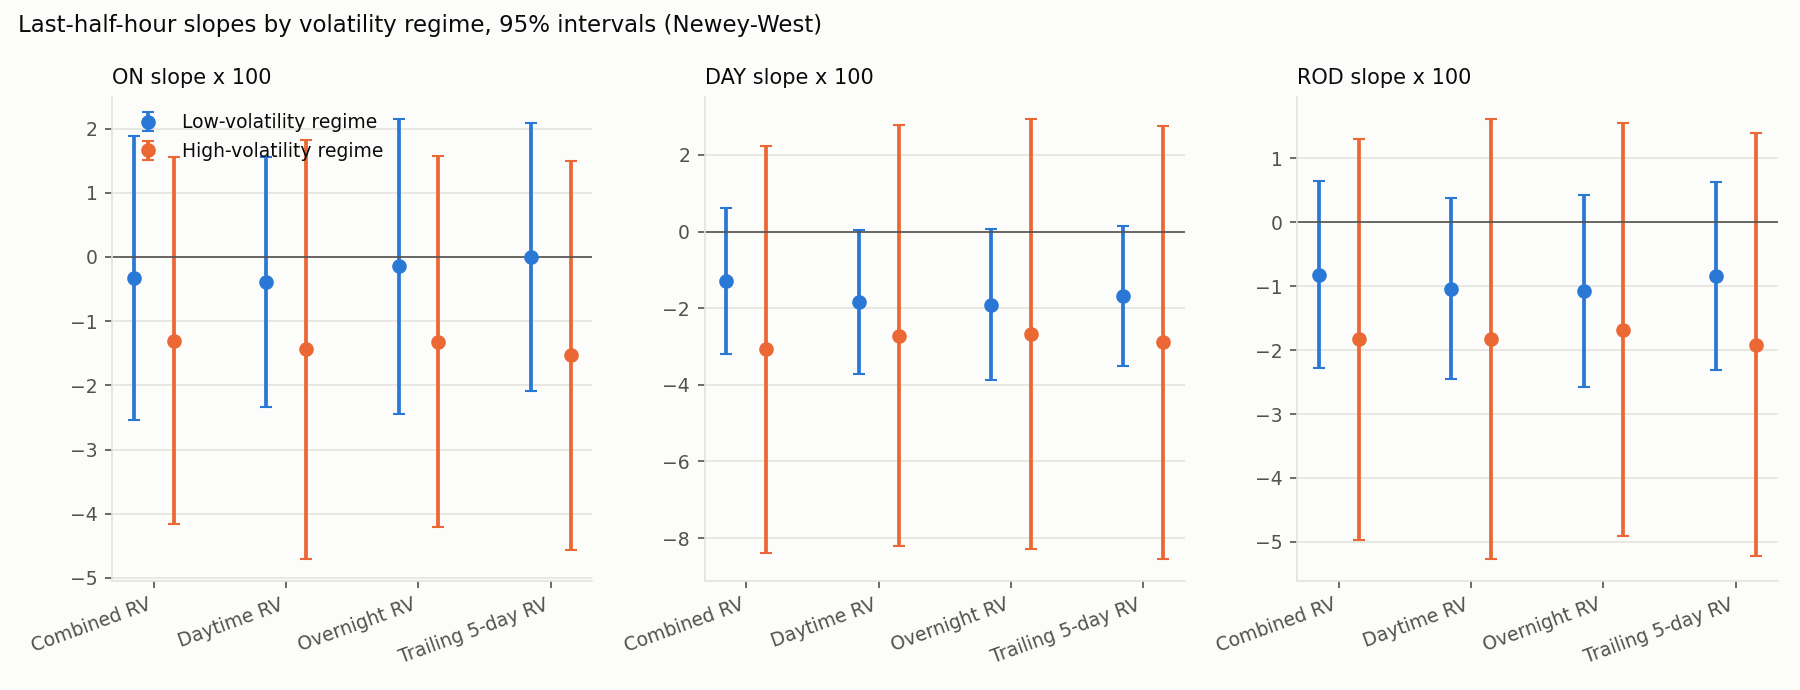

In [8]:
display(Image(filename=figures / "volatility_regimes_slopes.png", width=950))

In [9]:
fit = regressions[regressions["regime"].eq("combined_vol") & regressions["model"].isin(["base", "interaction"])]
fit.assign(estimate=estimate(fit, "coef_x100", "se_x100"))[["model", "term", "estimate", "ci_low_x100", "ci_high_x100", "t_stat", "p_value", "n", "adj_r2_pct"]].rename(columns={"estimate": "coef × 100 (SE)"})

,model,term,coef × 100 (SE),ci_low_x100,ci_high_x100,t_stat,p_value,n,adj_r2_pct
0,base,const,-0.02 (0.01),-0.048,0.007,-1.472,0.141,1186,0.619
1,base,on,-1.02 (1.08),-3.137,1.099,-0.943,0.346,1186,0.619
2,base,day,-2.29 (1.59),-5.413,0.826,-1.441,0.150,1186,0.619
3,interaction,const,-0.03 (0.01),-0.055,-0.005,-2.353,0.019,1186,0.563
4,interaction,on,-0.33 (1.13),-2.543,1.878,-0.295,0.768,1186,0.563
5,interaction,day,-1.29 (0.97),-3.194,0.617,-1.325,0.185,1186,0.563
6,interaction,high,0.03 (0.04),-0.043,0.102,0.792,0.428,1186,0.563
7,interaction,on:high,-0.97 (1.84),-4.572,2.630,-0.528,0.597,1186,0.563
8,interaction,day:high,-1.79 (2.94),-7.544,3.972,-0.608,0.543,1186,0.563


## 4. Out of sample

Expanding-window forecasts after 500 observations of the regime sample. Each interaction model is compared with the historical mean and with the base model it nests.

In [10]:
oos.assign(regime=oos["regime"].map(REGIMES))

,regime,measure,model,n,oos_forecasts,oos_r2_pct,clark_west_t,clark_west_p,oos_r2_vs_base_pct,clark_west_t_vs_base,clark_west_p_vs_base
0,Combined RV,rv_rod,base,1186,686,0.345,0.934,0.175,NaN,NaN,NaN
1,Combined RV,rv_rod,interaction,1186,686,-0.605,0.157,0.438,-0.953,-0.930,0.824
2,Combined RV,rv_rod,rod,1186,686,0.333,0.856,0.196,NaN,NaN,NaN
3,Combined RV,rv_rod,rod_interaction,1186,686,-0.438,0.228,0.410,-0.774,-1.115,0.867
4,Daytime RV,rv_day,base,1186,686,0.345,0.934,0.175,NaN,NaN,NaN
5,Daytime RV,rv_day,interaction,1186,686,-1.151,-0.379,0.648,-1.502,-1.752,0.960
6,Daytime RV,rv_day,rod,1186,686,0.333,0.856,0.196,NaN,NaN,NaN
7,Daytime RV,rv_day,rod_interaction,1186,686,-0.898,-0.242,0.596,-1.235,-2.189,0.986
8,Overnight RV,rv_on,base,1186,686,0.345,0.934,0.175,NaN,NaN,NaN
9,Overnight RV,rv_on,interaction,1186,686,-0.900,-0.045,0.518,-1.249,-0.679,0.751


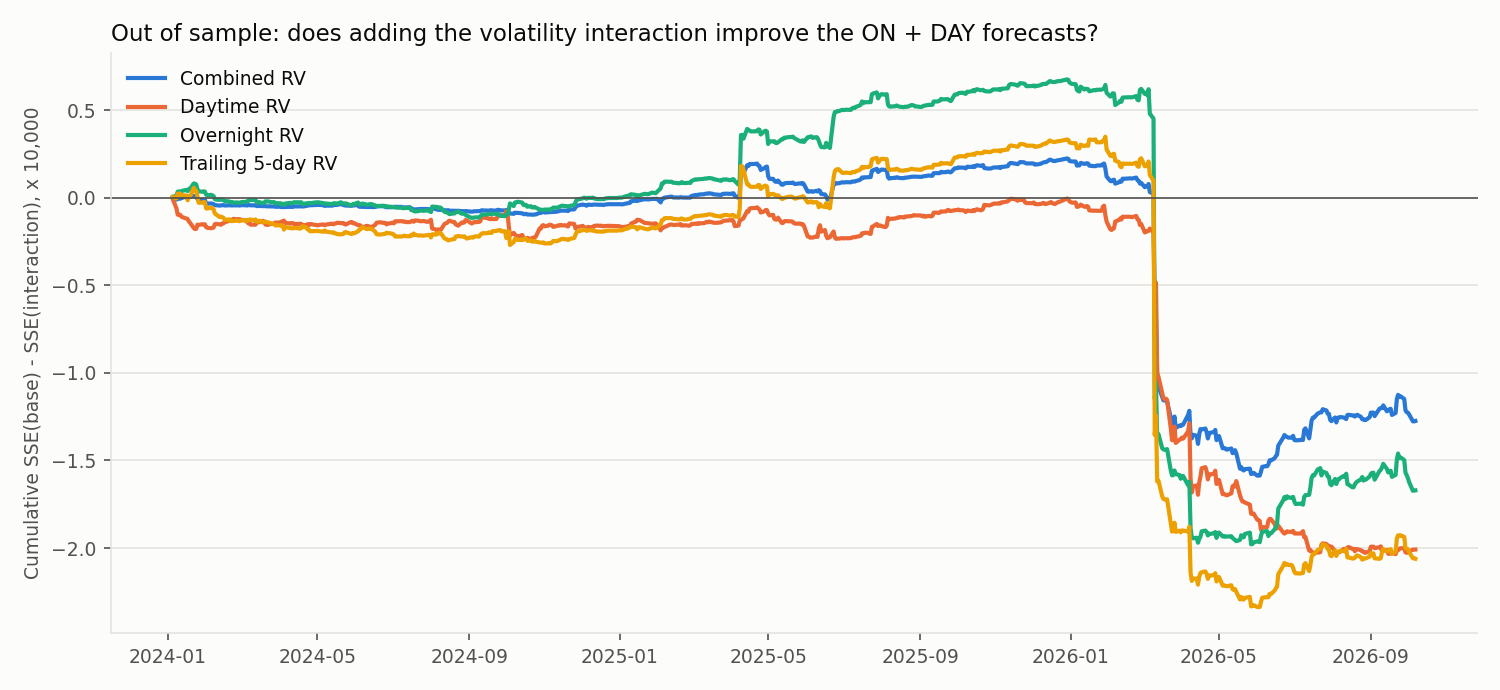

In [11]:
display(Image(filename=figures / "volatility_regimes_oos.png", width=950))

## 5. Robustness and stability

Other thresholds, log returns, and excluded dates; then the baseline regime's slopes by calendar year.

In [12]:
variants = robustness[robustness["predictor"].isin(["on", "day"])].assign(
	regime=robustness["regime"].map(REGIMES), difference=estimate(robustness, "difference_x100", "se_difference_x100")
)
variants.pivot_table(index=["variant", "regime"], columns="predictor", values="difference", aggfunc="first").join(
	variants.groupby(["variant", "regime"])["wald_p"].first()
).rename(columns={"on": "ON high − low (SE)", "day": "DAY high − low (SE)"})

DAY high − low (SE)  \
variant                        regime                                  
exclude:exclude_2026_03_10     Combined RV               0.70 (2.11)   
                               Daytime RV                1.70 (2.19)   
                               Overnight RV              1.89 (2.22)   
                               Trailing 5-day RV         1.48 (2.11)   
exclude:exclude_degraded_dates Combined RV              -2.05 (2.94)   
                               Daytime RV               -0.93 (3.05)   
                               Overnight RV             -0.78 (3.12)   
                               Trailing 5-day RV        -1.26 (3.05)   
exclude:exclude_roll_dates     Combined RV              -2.45 (3.01)   
                               Daytime RV               -1.23 (3.14)   
                               Overnight RV             -1.07 (3.22)   
                               Trailing 5-day RV        -1.69 (3.16)   
log_returns                    Combined RV              -1.83 (2.94)   
                               Daytime RV               -0.93 (3.05)   
                               Overnight RV             -0.81 (3.12)   
                               Trailing 5-day RV        -1.27 (3.07)   
threshold:expanding_median     Combined RV              -0.81 (2.38)   
                               Daytime RV               -1.67 (2.31)   
                               Overnight RV             -0.48 (2.53)   
                               Trailing 5-day RV        -0.51 (2.42)   
threshold:expanding_q90        Combined RV              -2.10 (4.46)   
                               Daytime RV               -3.99 (4.15)   
                               Overnight RV             -2.13 (4.89)   
                               Trailing 5-day RV        -1.16 (5.09)   
threshold:training_500_q75     Combined RV              -1.91 (3.19)   
                               Daytime RV               -1.37 (3.17)   
                               Overnight RV             -0.74 (3.25)   
                               Trailing 5-day RV        -2.66 (3.38)   

                                                 ON high − low (SE)  wald_p  
variant                        regime                                        
exclude:exclude_2026_03_10     Combined RV             -0.07 (1.65)   0.945  
                               Daytime RV               0.03 (1.69)   0.740  
                               Overnight RV            -0.25 (1.70)   0.685  
                               Trailing 5-day RV       -0.57 (1.67)   0.717  
exclude:exclude_degraded_dates Combined RV             -1.21 (1.85)   0.706  
                               Daytime RV              -1.22 (1.94)   0.818  
                               Overnight RV            -1.30 (1.89)   0.790  
                               Trailing 5-day RV       -1.54 (1.85)   0.703  
exclude:exclude_roll_dates     Combined RV             -1.13 (1.91)   0.678  
                               Daytime RV              -0.51 (1.96)   0.918  
                               Overnight RV            -1.23 (1.95)   0.813  
                               Trailing 5-day RV       -0.95 (1.91)   0.823  
log_returns                    Combined RV             -0.92 (1.85)   0.782  
                               Daytime RV              -0.93 (1.95)   0.881  
                               Overnight RV            -1.11 (1.90)   0.841  
                               Trailing 5-day RV       -1.44 (1.87)   0.735  
threshold:expanding_median     Combined RV             -1.79 (1.89)   0.632  
                               Daytime RV              -0.88 (1.78)   0.729  
                               Overnight RV            -0.91 (1.95)   0.895  
                               Trailing 5-day RV       -2.05 (1.84)   0.534  
threshold:expanding_q90        Combined RV             -1.12 (2.21)   0.845  
                               Daytime RV               0.16 (2.08)   0.553  
                

In [13]:
by_year.assign(low=estimate(by_year, "slope_low_x100", "se_low_x100"), high=estimate(by_year, "slope_high_x100", "se_high_x100"))[["year", "predictor", "n_low", "n_high", "low", "high"]]

,year,predictor,n_low,n_high,low,high
0,2022,on,102,147,-4.52 (3.76),-1.28 (2.84)
1,2022,day,102,147,2.97 (2.82),-0.10 (2.67)
2,2023,on,236,12,1.15 (2.15),1.38 (8.77)
3,2023,day,236,12,-1.59 (1.95),-4.99 (10.40)
4,2024,on,236,13,0.87 (2.31),-7.26 (8.19)
5,2024,day,236,13,-2.10 (1.37),3.75 (6.24)
6,2025,on,224,24,-0.30 (2.14),2.50 (1.41)
7,2025,day,224,24,-2.32 (1.87),9.37 (2.31)
8,2026,on,52,140,0.06 (3.02),-1.59 (1.83)
9,2026,day,52,140,-2.03 (3.62),-10.47 (4.25)


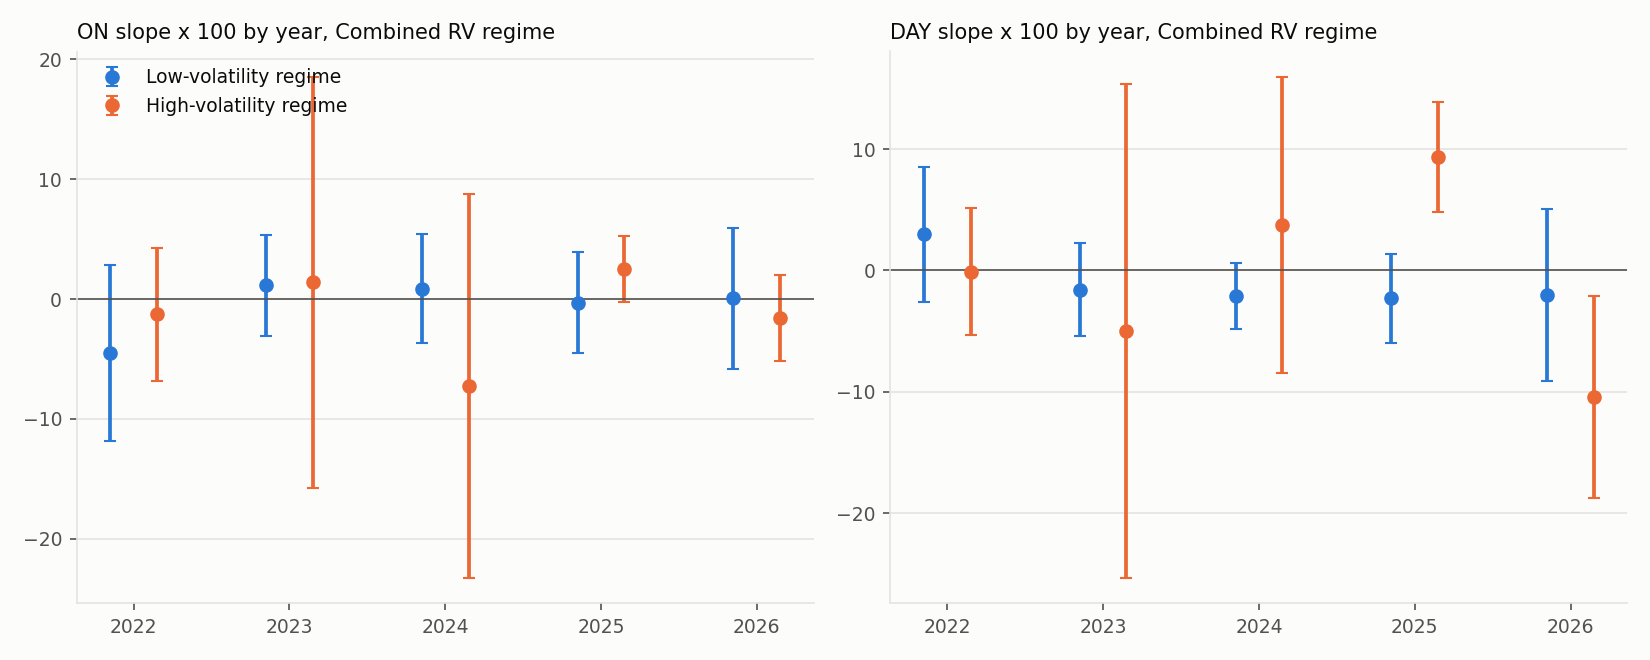

In [14]:
display(Image(filename=figures / "volatility_regimes_by_year.png", width=950))